<a href="https://colab.research.google.com/github/Rajapaksha-RMDD/pusl3123-ai-ml-coursework/blob/main/Exercise_1_MLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torchvision
import torchvision.transforms as transforms

# Convert images to PyTorch tensors and normalize pixel values
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# Download and load training data (50,000 images)
trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=64,
                                          shuffle=True, num_workers=2)

# Download and load test data (10,000 images)
testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=64,
                                         shuffle=False, num_workers=2)

print(f"Training images: {len(trainset)}")
print(f"Test images: {len(testset)}")

100%|██████████| 170M/170M [16:52<00:00, 168kB/s]


Training images: 50000
Test images: 10000


In [2]:
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

# 1. Define the MLP Architecture
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        # Flattened input (3072) to first hidden layer
        self.fc1 = nn.Linear(3 * 32 * 32, 512) # Trainable Layer 1
        # First hidden layer to second hidden layer
        self.fc2 = nn.Linear(512, 128)         # Trainable Layer 2
        # Second hidden layer to 10 output classes
        self.fc3 = nn.Linear(128, 10)          # Trainable Layer 3

    def forward(self, x):
        # Flatten the image tensor from (batch_size, 3, 32, 32) to (batch_size, 3072)
        x = x.view(-1, 3 * 32 * 32)
        # Apply ReLU activation function to hidden layers
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        # No activation function on the final layer (CrossEntropyLoss handles it)
        x = self.fc3(x)
        return x

# 2. Initialize the model and move it to the GPU for faster training
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = MLP().to(device)

# 3. Select the Loss Function and Optimisation Algorithm
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print(model)
print(f"Model successfully loaded onto: {device}")

MLP(
  (fc1): Linear(in_features=3072, out_features=512, bias=True)
  (fc2): Linear(in_features=512, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=10, bias=True)
)
Model successfully loaded onto: cuda:0


Starting Training...
Epoch [1/15] | Train Loss: 1.6399 | Train Acc: 41.99% | Val Loss: 1.4806 | Val Acc: 47.64%
Epoch [2/15] | Train Loss: 1.4311 | Train Acc: 49.32% | Val Loss: 1.4345 | Val Acc: 49.76%
Epoch [3/15] | Train Loss: 1.3279 | Train Acc: 53.10% | Val Loss: 1.3987 | Val Acc: 50.88%
Epoch [4/15] | Train Loss: 1.2358 | Train Acc: 56.43% | Val Loss: 1.3632 | Val Acc: 52.52%
Epoch [5/15] | Train Loss: 1.1640 | Train Acc: 58.89% | Val Loss: 1.3687 | Val Acc: 52.77%
Epoch [6/15] | Train Loss: 1.0905 | Train Acc: 61.31% | Val Loss: 1.4132 | Val Acc: 53.10%
Epoch [7/15] | Train Loss: 1.0214 | Train Acc: 63.75% | Val Loss: 1.3922 | Val Acc: 53.15%
Epoch [8/15] | Train Loss: 0.9550 | Train Acc: 66.24% | Val Loss: 1.4135 | Val Acc: 53.98%
Epoch [9/15] | Train Loss: 0.8983 | Train Acc: 68.14% | Val Loss: 1.4580 | Val Acc: 53.10%
Epoch [10/15] | Train Loss: 0.8377 | Train Acc: 70.41% | Val Loss: 1.5111 | Val Acc: 52.46%
Epoch [11/15] | Train Loss: 0.7783 | Train Acc: 72.54% | Val Loss: 1

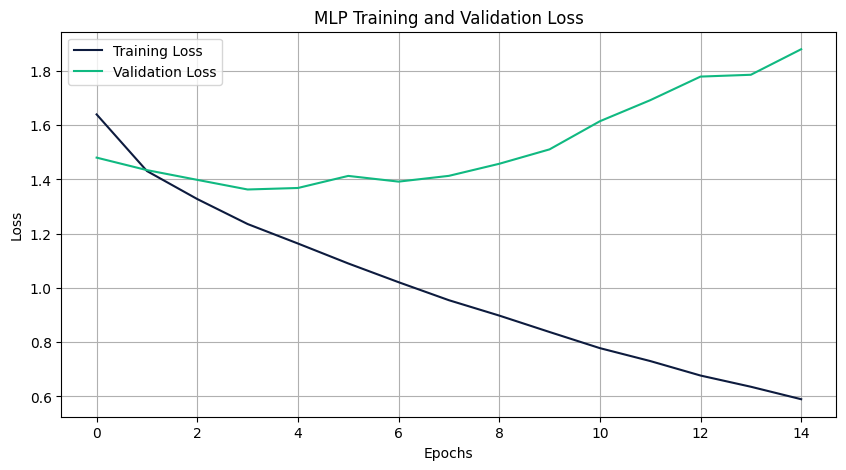

In [3]:
import matplotlib.pyplot as plt

epochs = 15
train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

print("Starting Training...")

for epoch in range(epochs):
    # --- Training Phase ---
    model.train()
    running_loss, correct_train, total_train = 0.0, 0, 0

    for inputs, labels in trainloader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad() # Clear previous gradients

        outputs = model(inputs) # Forward pass
        loss = criterion(outputs, labels) # Calculate loss
        loss.backward() # Backward pass
        optimizer.step() # Update weights

        running_loss += loss.item()

        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / len(trainloader)
    epoch_train_acc = 100 * correct_train / total_train
    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_acc)

    # --- Validation Phase ---
    model.eval()
    val_loss, correct_val, total_val = 0.0, 0, 0

    with torch.no_grad(): # Disable gradient tracking during validation
        for inputs, labels in testloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item()

            _, predicted = torch.max(outputs.data, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()

    epoch_val_loss = val_loss / len(testloader)
    epoch_val_acc = 100 * correct_val / total_val
    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_acc)

    print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}% | Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:.2f}%")

print("Training Complete!")

# --- Plotting the Loss Curve ---
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Training Loss', color='#0D1B3E')
plt.plot(val_losses, label='Validation Loss', color='#10b981')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('MLP Training and Validation Loss')
plt.legend()
plt.grid(True)
plt.show()